# Postpartum Anxiety Screening with Machine Learning

Data: Kaggle *PostPartum Depression* survey. Goal: predict the survey answer **Feeling anxious** from the other questions.
This is symptom screening, not a medical diagnosis.

## Step 1: Import libraries and settings

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier,
                              VotingClassifier, StackingClassifier)
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss, confusion_matrix, RocCurveDisplay, ConfusionMatrixDisplay
from sklearn.model_selection import (StratifiedGroupKFold, StratifiedKFold, RandomizedSearchCV,
                                     cross_validate, cross_val_predict)
from sklearn.naive_bayes import BernoulliNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from scipy.stats import loguniform

warnings.filterwarnings("ignore")

SEED = 42
GAP_LIMIT = 0.10      # a model whose train AUC is more than this above its validation AUC is treated as overfitted
Path("results").mkdir(exist_ok=True)

## Step 2: Load the data

In [2]:
raw = pd.read_csv("post natal data.csv")
raw.head()

,Timestamp,Age,Feeling sad or Tearful,Irritable towards baby & partner,Trouble sleeping at night,Problems concentrating or making decision,Overeating or loss of appetite,Feeling anxious,Feeling of guilt,Problems of bonding with baby,Suicide attempt
0,6/14/2022 20:02,35-40,Yes,Yes,Two or more days a week,Yes,Yes,Yes,No,Yes,Yes
1,6/14/2022 20:03,40-45,Yes,No,No,Yes,Yes,No,Yes,Yes,No
2,6/14/2022 20:04,35-40,Yes,No,Yes,Yes,Yes,Yes,No,Sometimes,No
3,6/14/2022 20:05,35-40,Yes,Yes,Yes,Yes,No,Yes,Maybe,No,No
4,6/14/2022 20:06,40-45,Yes,No,Two or more days a week,Yes,No,Yes,No,Yes,No


## Step 3: Check data quality
Identical rows can end up in both training and test data, which makes a model look better than it is.

In [3]:
target_name = "Feeling anxious"
question_names = [c for c in raw.columns if c not in ["Timestamp", target_name]]

X_raw = raw[question_names].astype(object)
y_raw = (raw[target_name] == "Yes").astype(int).to_numpy()

# one text label per distinct combination of answers
pattern = X_raw.fillna("missing").astype(str).agg("|".join, axis=1)
pattern_id = pd.factorize(pattern)[0]
is_repeat = (pattern + "|" + pd.Series(y_raw).astype(str)).duplicated().to_numpy()

quality = pd.Series({
    "Rows": len(raw),
    "Missing cells": int(X_raw.isna().sum().sum()),
    "Distinct answer patterns": int((~is_repeat).sum()),
    "Rows that repeat an earlier row": int(is_repeat.sum()),
    "Anxious share (all rows)": round(y_raw.mean(), 3),
    "Anxious share (repeats removed)": round(y_raw[~is_repeat].mean(), 3),
})
quality

Rows                               1503.000
Missing cells                        27.000
Distinct answer patterns            326.000
Rows that repeat an earlier row    1177.000
Anxious share (all rows)              0.652
Anxious share (repeats removed)       0.580
dtype: float64

## Step 4: Prepare the data
We keep each distinct response once. Missing answers are filled and answers are one-hot encoded inside the model pipeline.

In [4]:
X = X_raw[~is_repeat].reset_index(drop=True)
y = y_raw[~is_repeat]
groups = pattern_id[~is_repeat]        # rows with the same answers share a group


def new_prep():
    return Pipeline([("fill", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])


def with_prep(model):
    return Pipeline([("prep", new_prep()), ("model", model)])


print(X.shape)

(326, 9)


## Step 5: Split into training and test data
20% of the data is locked away as the test set and only used in Step 14.

In [5]:
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_rows, test_rows = next(splitter.split(X, y, groups))

X_train, y_train, g_train = X.iloc[train_rows], y[train_rows], groups[train_rows]
X_test, y_test = X.iloc[test_rows], y[test_rows]
print("Train:", len(y_train), "| Test:", len(y_test))

Train: 260 | Test: 66


## Step 6: Choose candidate models
With only nine simple questions and about 260 training rows, simple models should do well. Complex models are included to see whether they add anything.

| Model | Why it is included |
|---|---|
| Dummy | Baseline: always predicts the average |
| Logistic regression | Standard for questionnaires, easy to explain |
| Naive Bayes | Simple and fast for yes/no answers |
| Decision tree | Easy-to-read rules |
| SVM | Common in related studies |
| Random forest | Handles interactions between answers |
| Gradient boosting | Strong on tables, can overfit |
| Voting / stacking | Check whether combining models helps |

The list goes from simplest to most complex.

In [6]:
members = [("lr", LogisticRegression(max_iter=2000)),
           ("rf", RandomForestClassifier(n_estimators=300, max_depth=4, min_samples_leaf=3, random_state=SEED)),
           ("gb", HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=100,
                                                 min_samples_leaf=10, l2_regularization=1.0, random_state=SEED))]

models = {
    "Dummy": DummyClassifier(strategy="prior"),
    "Logistic regression": with_prep(LogisticRegression(max_iter=2000)),
    "Naive Bayes": with_prep(BernoulliNB()),
    "Decision tree": with_prep(DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=SEED)),
    "SVM": with_prep(SVC(probability=True, random_state=SEED)),
    "Random forest": with_prep(members[1][1]),
    "Gradient boosting": with_prep(members[2][1]),
    "Voting ensemble": with_prep(VotingClassifier(members, voting="soft")),
    "Stacking ensemble": with_prep(StackingClassifier(members, final_estimator=LogisticRegression(max_iter=2000), cv=5)),
}
list(models)

['Dummy',
 'Logistic regression',
 'Naive Bayes',
 'Decision tree',
 'SVM',
 'Random forest',
 'Gradient boosting',
 'Voting ensemble',
 'Stacking ensemble']

## Step 7: Compare the models with cross-validation (training data only)
Each model is trained and checked on 15 different splits. A big gap between train and validation AUC means the model is overfitting.

In [7]:
folds = []
for repeat in range(3):
    splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + repeat)
    folds = folds + list(splitter.split(X_train, y_train, g_train))

rows = []
fold_scores = {}
for name, model in models.items():
    result = cross_validate(model, X_train, y_train, cv=folds, scoring="roc_auc", return_train_score=True)
    fold_scores[name] = result["test_score"]
    rows.append({"Model": name,
                 "Train AUC": result["train_score"].mean(),
                 "Validation AUC": result["test_score"].mean(),
                 "SE": pd.Series(result["test_score"]).sem()})

cv_table = pd.DataFrame(rows).set_index("Model")
cv_table["Gap"] = cv_table["Train AUC"] - cv_table["Validation AUC"]
cv_table.to_csv("results/cv_comparison.csv")
cv_table.round(3)

,Train AUC,Validation AUC,SE,Gap
Model,,,,
Dummy,0.500,0.500,0.000,0.000
Logistic regression,0.871,0.805,0.009,0.066
Naive Bayes,0.859,0.817,0.007,0.041
Decision tree,0.842,0.771,0.015,0.071
SVM,0.978,0.840,0.010,0.138
Random forest,0.938,0.842,0.009,0.097
Gradient boosting,0.952,0.825,0.011,0.128
Voting ensemble,0.929,0.830,0.010,0.099
Stacking ensemble,0.932,0.831,0.010,0.101


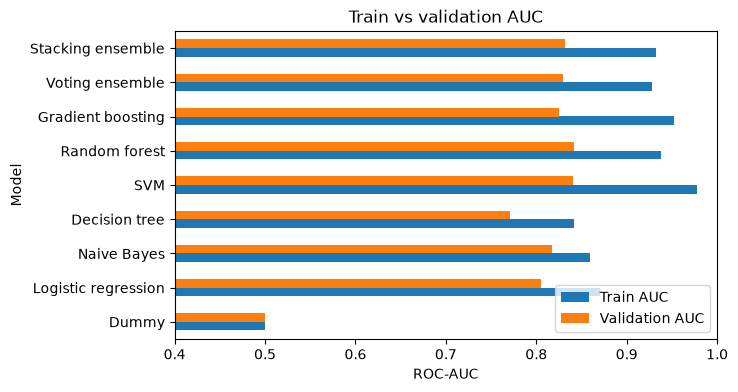

In [8]:
cv_table[["Train AUC", "Validation AUC"]].plot.barh(figsize=(7, 4))
plt.xlabel("ROC-AUC")
plt.title("Train vs validation AUC")
plt.xlim(0.4, 1.0)
plt.show()

## Step 8: Are the differences real?
Each model is compared with logistic regression on the 15 splits. The corrected t-test allows for the overlap between training sets; p-values are multiplied by the number of comparisons (Bonferroni).

In [9]:
def corrected_p_value(diff):
    n = len(diff)
    t = diff.mean() / np.sqrt((1 / n + 0.25) * diff.var(ddof=1))    # 0.25 = test size / train size in 5-fold CV
    return 2 * stats.t.sf(abs(t), n - 1)


rows = []
for name in models:
    if name in ["Dummy", "Logistic regression"]:
        continue
    diff = fold_scores[name] - fold_scores["Logistic regression"]
    rows.append({"Model": name, "AUC difference vs logistic regression": diff.mean(), "p": corrected_p_value(diff)})

vs_lr = pd.DataFrame(rows).set_index("Model")
vs_lr["p (Bonferroni)"] = (vs_lr["p"] * len(vs_lr)).clip(upper=1)
vs_lr.round(3)

,AUC difference vs logistic regression,p,p (Bonferroni)
Model,,,
Naive Bayes,0.012,0.406,1.000
Decision tree,-0.034,0.230,1.000
SVM,0.035,0.037,0.262
Random forest,0.037,0.009,0.064
Gradient boosting,0.020,0.263,1.000
Voting ensemble,0.025,0.028,0.198
Stacking ensemble,0.026,0.025,0.172


In [10]:
best_member = cv_table.loc[["Logistic regression", "Random forest", "Gradient boosting"], "Validation AUC"].idxmax()

rows = []
for ensemble in ["Voting ensemble", "Stacking ensemble"]:
    diff = fold_scores[ensemble] - fold_scores[best_member]
    rows.append({"Ensemble": ensemble, "Best single model": best_member, "AUC difference": diff.mean(), "p": corrected_p_value(diff)})
pd.DataFrame(rows).round(3)

,Ensemble,Best single model,AUC difference,p
0,Voting ensemble,Random forest,-0.012,0.075
1,Stacking ensemble,Random forest,-0.010,0.122


In [11]:
# Do the three ensemble members make the same mistakes? (1 = always wrong together)
mistakes = pd.DataFrame()
for name in ["Logistic regression", "Random forest", "Gradient boosting"]:
    probs = cross_val_predict(models[name], X_train, y_train, cv=StratifiedGroupKFold(5, shuffle=True, random_state=SEED),
                              groups=g_train, method="predict_proba")[:, 1]
    mistakes[name] = ((probs >= 0.5).astype(int) != y_train).astype(int)
mistakes.corr().round(2)

,Logistic regression,Random forest,Gradient boosting
Logistic regression,1.00,0.70,0.72
Random forest,0.70,1.00,0.71
Gradient boosting,0.72,0.71,1.00


## Step 9: Select the final model and tune it
Rules (training data only): 1) drop models that overfit (gap above `GAP_LIMIT`); 2) keep models within one standard error of the best; 3) take the simplest of those.
Tuning is only kept if it also helps in a nested cross-validation.

In [12]:
candidates = cv_table.drop("Dummy")
candidates = candidates[candidates["Gap"] <= GAP_LIMIT]

best_name = candidates["Validation AUC"].idxmax()
cutoff = candidates.loc[best_name, "Validation AUC"] - candidates.loc[best_name, "SE"]
good_enough = candidates[candidates["Validation AUC"] >= cutoff]

selected = good_enough.index[0]          # first = simplest
print("Selected model:", selected)
good_enough.round(3)

Selected model: Random forest


,Train AUC,Validation AUC,SE,Gap
Model,,,,
Random forest,0.938,0.842,0.009,0.097


In [13]:
param_grids = {
    "Logistic regression": {"model__C": loguniform(1e-3, 1e2)},
    "SVM": {"model__C": loguniform(0.1, 50), "model__gamma": loguniform(1e-3, 1)},
    "Decision tree": {"model__max_depth": [2, 3, 4, 5], "model__min_samples_leaf": [5, 10, 20, 30]},
    "Random forest": {"model__n_estimators": [200, 400], "model__max_depth": [2, 3, 4, 6],
                      "model__min_samples_leaf": [1, 3, 5, 10], "model__max_features": ["sqrt", 0.5]},
    "Gradient boosting": {"model__learning_rate": loguniform(0.01, 0.2), "model__max_depth": [2, 3, 4],
                          "model__max_iter": [50, 100, 200], "model__min_samples_leaf": [5, 10, 20]},
}


def make_search():
    return RandomizedSearchCV(models[selected], param_grids[selected], n_iter=10, scoring="neg_log_loss",
                              cv=StratifiedGroupKFold(3, shuffle=True, random_state=SEED), random_state=SEED)


final_model = clone(models[selected]).fit(X_train, y_train)
validation_auc = cv_table.loc[selected, "Validation AUC"]

if selected in param_grids:
    tuned_scores = []
    for fit_rows, check_rows in folds:
        search = make_search()
        search.fit(X_train.iloc[fit_rows], y_train[fit_rows], groups=g_train[fit_rows])
        probs = search.predict_proba(X_train.iloc[check_rows])[:, 1]
        tuned_scores.append(roc_auc_score(y_train[check_rows], probs))
    tuned_auc = np.mean(tuned_scores)

    if tuned_auc > validation_auc:
        search = make_search()
        search.fit(X_train, y_train, groups=g_train)
        final_model = search.best_estimator_
        print(f"Tuning kept (validation AUC {validation_auc:.3f} -> {tuned_auc:.3f}):", search.best_params_)
        validation_auc = tuned_auc
    else:
        print(f"Tuning rejected (untuned {validation_auc:.3f}, tuned {tuned_auc:.3f}). Default settings are used.")

Tuning rejected (untuned 0.842, tuned 0.840). Default settings are used.


## Step 10: Which questions matter? Are they the same in every fold?
Each question is shuffled in turn; the bigger the AUC drop, the more the model relies on it.

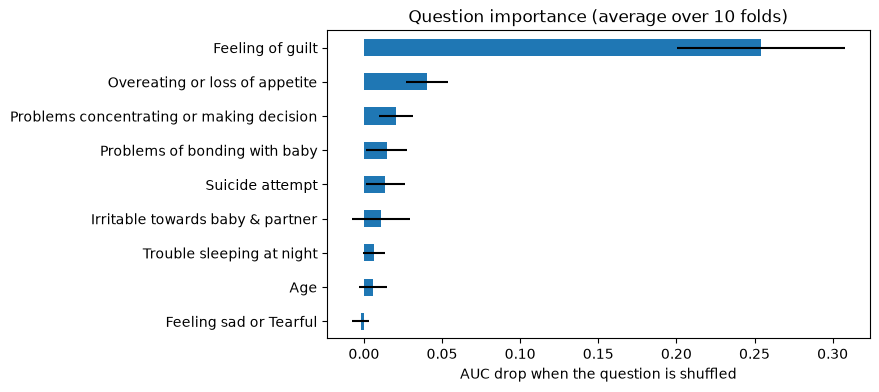

Feeling of guilt    10
Name: Folds where it ranks first, dtype: int64

In [14]:
importance_per_fold = []
for fit_rows, check_rows in folds[:10]:
    model = clone(final_model).fit(X_train.iloc[fit_rows], y_train[fit_rows])
    result = permutation_importance(model, X_train.iloc[check_rows], y_train[check_rows],
                                    scoring="roc_auc", n_repeats=10, random_state=SEED)
    importance_per_fold.append(result.importances_mean)

importance = pd.DataFrame(importance_per_fold, columns=X_train.columns)
average = importance.mean().sort_values()
average.plot.barh(xerr=importance.std()[average.index], figsize=(7, 4))
plt.xlabel("AUC drop when the question is shuffled")
plt.title("Question importance (average over 10 folds)")
plt.show()

importance.idxmax(axis=1).value_counts().rename("Folds where it ranks first")

## Step 11: How many questions are really needed?
In every fold the questions are ranked on the training part only, and the model is refitted with the top k.

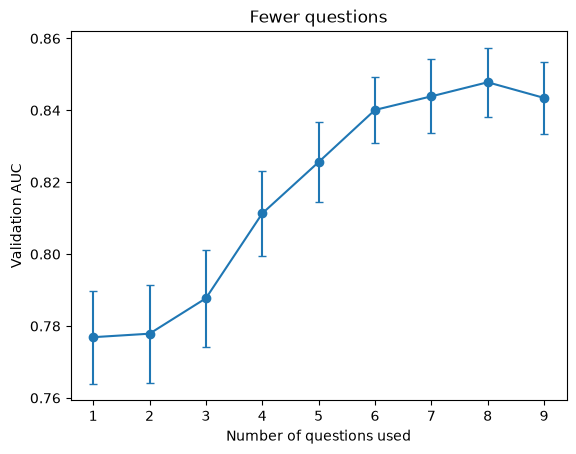

Fewest questions within one standard error of using all of them: 6


In [15]:
rows = []
for k in range(1, X_train.shape[1] + 1):
    scores = []
    for fit_rows, check_rows in folds:
        X_fit, X_check = X_train.iloc[fit_rows], X_train.iloc[check_rows]
        codes = OrdinalEncoder().fit_transform(X_fit.fillna("missing").astype(str))
        relevance = mutual_info_classif(codes, y_train[fit_rows], discrete_features=True, random_state=SEED)
        top_questions = X_fit.columns[np.argsort(relevance)[::-1][:k]]

        model = clone(final_model).fit(X_fit[top_questions], y_train[fit_rows])
        probs = model.predict_proba(X_check[top_questions])[:, 1]
        scores.append(roc_auc_score(y_train[check_rows], probs))
    rows.append({"Questions": k, "AUC": np.mean(scores), "SE": pd.Series(scores).sem()})

by_questions = pd.DataFrame(rows).set_index("Questions")
all_questions = by_questions.iloc[-1]
smallest = by_questions[by_questions["AUC"] >= all_questions["AUC"] - all_questions["SE"]].index.min()

plt.errorbar(by_questions.index, by_questions["AUC"], yerr=by_questions["SE"], marker="o", capsize=3)
plt.xlabel("Number of questions used")
plt.ylabel("Validation AUC")
plt.title("Fewer questions")
plt.show()
print("Fewest questions within one standard error of using all of them:", smallest)

## Step 12: Does label noise hurt?
Some training answers are flipped at random; the models are checked on clean data.

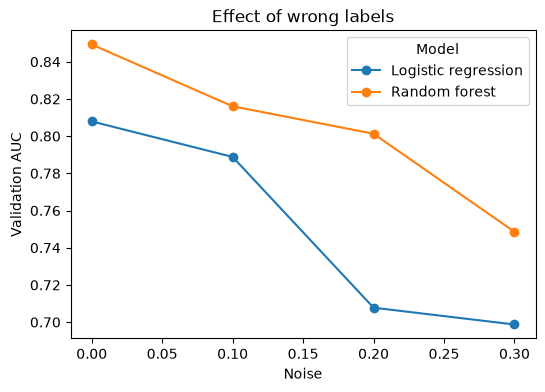

Model,Logistic regression,Random forest
Noise,,
0.0,0.808,0.849
0.1,0.789,0.816
0.2,0.708,0.801
0.3,0.699,0.749


In [16]:
rng = np.random.default_rng(SEED)
rows = []
for noise in [0, 0.1, 0.2, 0.3]:
    for name, model in [("Logistic regression", models["Logistic regression"]), (selected, final_model)]:
        scores = []
        for fit_rows, check_rows in folds[:5]:
            y_noisy = y_train[fit_rows].copy()
            flip = rng.random(len(y_noisy)) < noise
            y_noisy[flip] = 1 - y_noisy[flip]
            fitted = clone(model).fit(X_train.iloc[fit_rows], y_noisy)
            scores.append(roc_auc_score(y_train[check_rows], fitted.predict_proba(X_train.iloc[check_rows])[:, 1]))
        rows.append({"Noise": noise, "Model": name, "AUC": np.mean(scores)})

noise_table = pd.DataFrame(rows).pivot(index="Noise", columns="Model", values="AUC")
noise_table.plot(marker="o", figsize=(6, 4))
plt.ylabel("Validation AUC")
plt.title("Effect of wrong labels")
plt.show()
noise_table.round(3)

## Step 13: Results by age group
Cross-validated predictions on the training data. Groups are small, so treat this as a rough look.

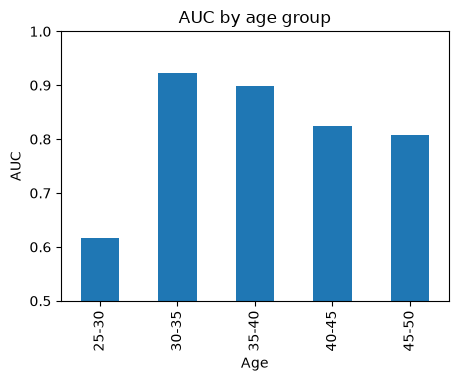

,Rows,Anxious share,AUC
Age,,,
25-30,38,0.47,0.62
30-35,60,0.57,0.92
35-40,64,0.59,0.90
40-45,55,0.56,0.82
45-50,43,0.70,0.81


In [17]:
probs = cross_val_predict(final_model, X_train, y_train, cv=StratifiedGroupKFold(5, shuffle=True, random_state=SEED),
                          groups=g_train, method="predict_proba")[:, 1]

rows = []
for age, positions in X_train.groupby("Age").indices.items():
    rows.append({"Age": age, "Rows": len(positions), "Anxious share": y_train[positions].mean(),
                 "AUC": roc_auc_score(y_train[positions], probs[positions])})
age_table = pd.DataFrame(rows).set_index("Age")

age_table["AUC"].plot.bar(ylim=(0.5, 1), figsize=(5, 3.5))
plt.ylabel("AUC")
plt.title("AUC by age group")
plt.show()
age_table.round(2)

## Step 14: Final test
The test set is used here for the first time, with the model chosen above.

In [18]:
def evaluate(model, X_data, y_data):
    probs = model.predict_proba(X_data)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_data, (probs >= 0.5).astype(int)).ravel()
    return {"AUC": roc_auc_score(y_data, probs), "Accuracy": (tp + tn) / len(y_data),
            "Sensitivity": tp / (tp + fn), "Specificity": tn / (tn + fp), "Brier score": brier_score_loss(y_data, probs)}


dummy = models["Dummy"].fit(X_train, y_train)
test_table = pd.DataFrame({"Selected model, train": evaluate(final_model, X_train, y_train),
                           "Selected model, test": evaluate(final_model, X_test, y_test),
                           "Dummy, test": evaluate(dummy, X_test, y_test)}).T
test_table.to_csv("results/test_scores.csv")

# 95% confidence interval for the test AUC by resampling test rows
probs_test = final_model.predict_proba(X_test)[:, 1]
boot_aucs = []
for _ in range(1000):
    pick = rng.integers(0, len(y_test), len(y_test))
    if y_test[pick].min() != y_test[pick].max():
        boot_aucs.append(roc_auc_score(y_test[pick], probs_test[pick]))
ci_low, ci_high = np.percentile(boot_aucs, [2.5, 97.5])

print(f"Test AUC 95% interval: {ci_low:.2f} to {ci_high:.2f}")
test_table.round(3)

Test AUC 95% interval: 0.67 to 0.90


,AUC,Accuracy,Sensitivity,Specificity,Brier score
"Selected model, train",0.930,0.815,0.901,0.697,0.133
"Selected model, test",0.795,0.788,0.842,0.714,0.182
"Dummy, test",0.500,0.576,1.000,0.000,0.244


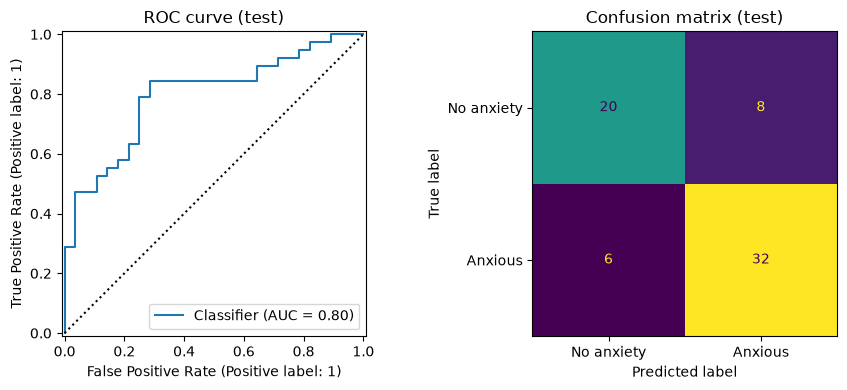

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
RocCurveDisplay.from_predictions(y_test, probs_test, ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k:")
axes[0].set_title("ROC curve (test)")
ConfusionMatrixDisplay.from_predictions(y_test, (probs_test >= 0.5).astype(int), ax=axes[1], colorbar=False,
                                        display_labels=["No anxiety", "Anxious"])
axes[1].set_title("Confusion matrix (test)")
plt.tight_layout()
plt.show()

In [20]:
# For information only (nothing was chosen from this table): all models on the test set
rows = []
for name, model in models.items():
    fitted = clone(model).fit(X_train, y_train)
    rows.append({"Model": name, "Validation AUC": cv_table.loc[name, "Validation AUC"],
                 "Test AUC": roc_auc_score(y_test, fitted.predict_proba(X_test)[:, 1])})
pd.DataFrame(rows).set_index("Model").round(3)

,Validation AUC,Test AUC
Model,,
Dummy,0.500,0.500
Logistic regression,0.805,0.788
Naive Bayes,0.817,0.790
Decision tree,0.771,0.747
SVM,0.840,0.787
Random forest,0.842,0.795
Gradient boosting,0.825,0.813
Voting ensemble,0.830,0.800
Stacking ensemble,0.831,0.804


## Step 15: Calibration, risk groups and decision curve
Probabilities are calibrated so that "0.7" means about 70% of such people were anxious. Group limits are taken from the **training** data only:
low = below the level that still catches 90% of anxious training cases; high = the first level where at least 80% are anxious.
These groups are rough model outputs, not medical risk categories.

In [21]:
calibrated = Pipeline([("prep", new_prep()),
                       ("model", CalibratedClassifierCV(clone(final_model.named_steps["model"]), method="sigmoid", cv=5))])

train_probs = cross_val_predict(calibrated, X_train, y_train, cv=StratifiedGroupKFold(5, shuffle=True, random_state=SEED),
                                groups=g_train, method="predict_proba")[:, 1]
calibrated.fit(X_train, y_train)
test_probs = calibrated.predict_proba(X_test)[:, 1]

low_limit = np.percentile(train_probs[y_train == 1], 10)
high_limit = 1.0
for limit in np.arange(0.3, 0.95, 0.01):
    above = train_probs >= limit
    if above.sum() >= 5 and y_train[above].mean() >= 0.8:
        high_limit = max(limit, low_limit)
        break

risk_group = np.where(test_probs < low_limit, "low", np.where(test_probs < high_limit, "medium", "high"))
risk_table = (pd.DataFrame({"group": risk_group, "anxious": y_test}).groupby("group")["anxious"]
              .agg(["count", "sum", "mean"]).reindex(["low", "medium", "high"]))
risk_table.columns = ["People", "Anxious", "Anxious share"]
risk_table.round(2)

,People,Anxious,Anxious share
group,,,
low,25,7,0.28
medium,3,1,0.33
high,38,30,0.79


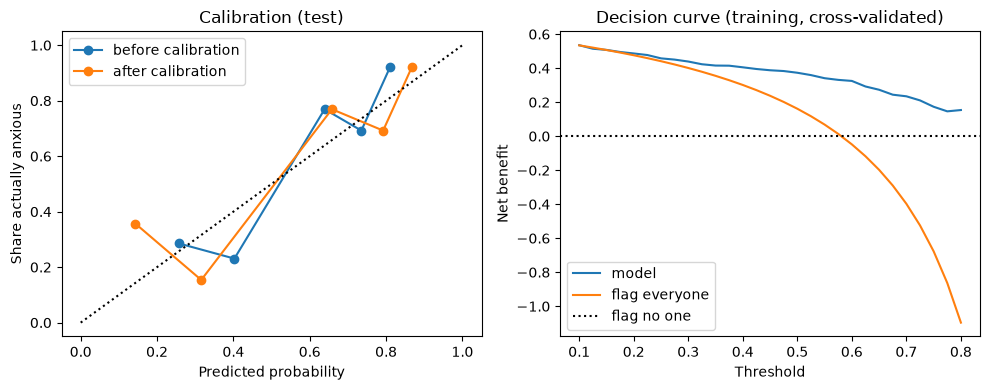

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for label, probs in [("before calibration", probs_test), ("after calibration", test_probs)]:
    observed, predicted = calibration_curve(y_test, probs, n_bins=5, strategy="quantile")
    axes[0].plot(predicted, observed, marker="o", label=label)
axes[0].plot([0, 1], [0, 1], "k:")
axes[0].set(xlabel="Predicted probability", ylabel="Share actually anxious", title="Calibration (test)")
axes[0].legend()

n = len(y_train)
cuts = np.linspace(0.1, 0.8, 29)
benefit_model, benefit_all = [], []
for cut in cuts:
    flagged = train_probs >= cut
    true_pos = (flagged & (y_train == 1)).sum() / n
    false_pos = (flagged & (y_train == 0)).sum() / n
    benefit_model.append(true_pos - false_pos * cut / (1 - cut))
    benefit_all.append(y_train.mean() - (1 - y_train.mean()) * cut / (1 - cut))
axes[1].plot(cuts, benefit_model, label="model")
axes[1].plot(cuts, benefit_all, label="flag everyone")
axes[1].axhline(0, color="k", linestyle=":", label="flag no one")
axes[1].set(xlabel="Threshold", ylabel="Net benefit", title="Decision curve (training, cross-validated)")
axes[1].legend()
plt.tight_layout()
plt.show()

## Step 16: Why we split by answer pattern
Same models on all 1,503 raw rows, with an ordinary split and with the grouped split.

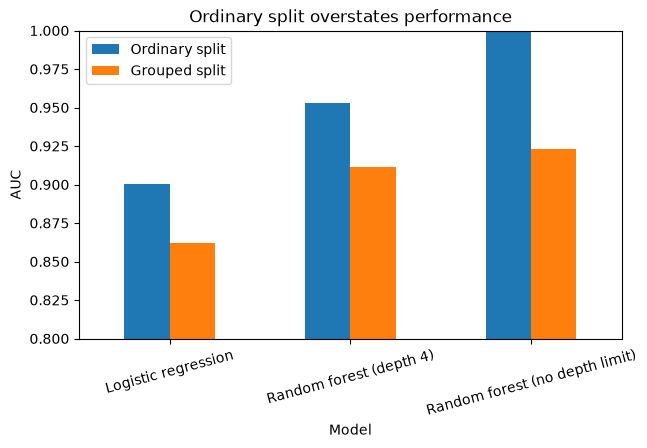

,Ordinary split,Grouped split,Inflation
Model,,,
Logistic regression,0.900,0.862,0.038
Random forest (depth 4),0.953,0.911,0.042
Random forest (no depth limit),0.999,0.923,0.076


In [23]:
def average_auc(model, grouped):
    scores = []
    for repeat in range(3):
        if grouped:
            splits = StratifiedGroupKFold(5, shuffle=True, random_state=SEED + repeat).split(X_raw, y_raw, pattern_id)
        else:
            splits = StratifiedKFold(5, shuffle=True, random_state=SEED + repeat).split(X_raw, y_raw)
        for fit_rows, check_rows in splits:
            fitted = clone(model).fit(X_raw.iloc[fit_rows], y_raw[fit_rows])
            scores.append(roc_auc_score(y_raw[check_rows], fitted.predict_proba(X_raw.iloc[check_rows])[:, 1]))
    return np.mean(scores)


leak_models = {"Logistic regression": models["Logistic regression"],
               "Random forest (depth 4)": models["Random forest"],
               "Random forest (no depth limit)": with_prep(RandomForestClassifier(n_estimators=300, random_state=SEED))}

rows = []
for name, model in leak_models.items():
    rows.append({"Model": name, "Ordinary split": average_auc(model, False), "Grouped split": average_auc(model, True)})
leak_table = pd.DataFrame(rows).set_index("Model")
leak_table["Inflation"] = leak_table["Ordinary split"] - leak_table["Grouped split"]

leak_table[["Ordinary split", "Grouped split"]].plot.bar(figsize=(7, 4), ylim=(0.8, 1.0))
plt.ylabel("AUC")
plt.title("Ordinary split overstates performance")
plt.xticks(rotation=15)
plt.show()
leak_table.round(3)

## Step 17: Summary

In [24]:
pd.Series({
    "Selected model": selected,
    "Train AUC": round(test_table.loc["Selected model, train", "AUC"], 3),
    "Cross-validation AUC": round(validation_auc, 3),
    "Test AUC": round(test_table.loc["Selected model, test", "AUC"], 3),
    "Test AUC 95% interval": f"{ci_low:.2f} to {ci_high:.2f}",
    "Dummy test AUC": round(test_table.loc["Dummy, test", "AUC"], 3),
    "Test sensitivity": round(test_table.loc["Selected model, test", "Sensitivity"], 2),
    "Test specificity": round(test_table.loc["Selected model, test", "Specificity"], 2),
    "Test set size": len(y_test),
    "Fewest questions needed": smallest,
    "Average leakage inflation (AUC)": round(leak_table["Inflation"].mean(), 3),
}).to_frame("Result")

,Result
Selected model,Random forest
Train AUC,0.93
Cross-validation AUC,0.842
Test AUC,0.795
Test AUC 95% interval,0.67 to 0.90
Dummy test AUC,0.5
Test sensitivity,0.84
Test specificity,0.71
Test set size,66
Fewest questions needed,6


Numbers come from the run saved in this notebook.

- **Chosen model: random forest.** The SVM, gradient boosting and stacking were dropped for overfitting; the forest was the only model left within one standard error of the best. Simple models were close (logistic regression 0.81, naive Bayes 0.82 vs 0.84 validation AUC), and after the multiple-comparison correction no model is clearly better than logistic regression (forest p = 0.064). Tuning did not improve the forest, so default settings were kept.
- **Training vs testing.** AUC is 0.93 on training data, 0.84 in cross-validation and **0.80 on the test set** (95% interval 0.67 to 0.90), against 0.50 for the dummy baseline. Sensitivity is 0.84 and specificity 0.71 at a 0.5 cut-off. The drop from training to test shows some overfitting, but it is modest. With only 66 test cases the interval is wide, and every model scores about 0.75 to 0.81 on the test set, so the test set cannot tell the models apart.
- **Ensembles do not help.** Voting and stacking are no better than the forest alone, and their members make correlated mistakes (about 0.70 to 0.72).
- **Questions.** *Feeling of guilt* is the most important question in all 10 folds. Six of the nine questions are enough to stay within one standard error of using all nine.
- **Wrong labels.** The forest stays ahead of logistic regression as more training labels are flipped (0.85 vs 0.81 clean, 0.75 vs 0.70 with 30% flipped).
- **Age groups.** Performance is weakest for ages 25 to 30 (AUC 0.62) and between 0.81 and 0.92 for the others; groups are small.
- **Risk groups.** The low group is 28% anxious and the high group 79%, but the medium group has only 3 people. These are rough model outputs, not medical risk categories.
- **Split by pattern.** Using an ordinary split on the raw rows overstates AUC by about 0.04 to 0.08, and an unlimited forest reaches 0.999 by memorising repeated rows.
- **Limits.** The target is one self-reported answer (not a diagnosis); the questions describe current symptoms (not early prediction); the data source is undocumented and 78% of rows repeat; the test set is small; no outside data was used.